# FNN — Duffing: identificação e avaliação dinâmica

**Projeto:** Data-Driven Dynamics and Control · 27/11/2026  
**Fundamentação:** [FNN.ipynb](FNN.ipynb) · **Referência experimental:** [GP_Duffing.ipynb](../GP/GP_Duffing.ipynb) · [Artigo-base, §5.1.1](https://arxiv.org/html/2512.06315).

Experimento próprio, não reprodução de resultados do artigo. Vamos aprender o mapa discreto do Duffing com estados completos, sem entregar sua equação à rede. Pergunta: **uma boa regressão de um passo é suficiente para reproduzir a dinâmica?** Compararemos persistência, FNN direta e FNN residual, mantendo os dados, arquitetura e orçamento de treinamento fixos. Depois investigaremos ruído, extrapolação e estabilidade local.

Execute as células em ordem. As 30 redes (2 parametrizações × 5 níveis de ruído × 3 sementes) são treinadas em paralelo vetorial na CPU, com parâmetros, gradientes, estados do Adam e critérios de parada independentes. Isso reduz o tempo de execução sem misturar os problemas de otimização. Não há treinamento multi-step nem certificado de estabilidade nesta etapa.

## 1. Planta e geração dos dados

Preservamos o benchmark modificado dos experimentos anteriores:
$$
\dot{x}_1=x_2,\quad \dot{x}_2=-2x_2-x_1\cos(x_1+x_2)+u.
$$
O integrador RK4 com $dt=0.01$ s e entrada constante em cada intervalo define o mapa de referência $F(x,u)$. A rede nunca chama a equação da planta. Geramos 400 transições de treino como no código do GP (seed 156; primeiro os estados, depois as entradas), e conjuntos independentes de validação (200) e teste (1.000). Não são 400 trajetórias longas: cada amostra é uma transição independente. Mantemos a região de amostragem $[-1,1]^3$. A descrição de ruído do GP menciona 1.000, mas seu código usa 400.

Python 3.13.5 | Torch 2.10.0+cpu | NumPy 2.3.5
RMSE de persistência (teste): [0.00573096 0.01216564]


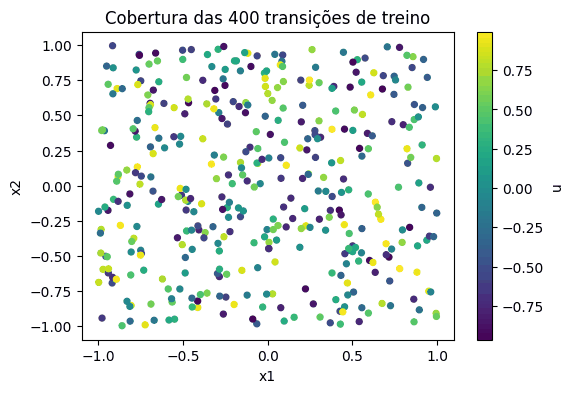

In [1]:
import time, copy, platform
import numpy as np
import torch
from torch import nn
from scipy.optimize import root
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

torch.set_num_threads(1)
DT, N_TRAIN, BATCH, EPOCHS, PATIENCE = .01, 400, 32, 2000, 100
SEEDS, NOISES, MODES = (156,157,158), (0,1,3,5,10), ('direta','residual')
LR, DTYPE = 1e-3, torch.float64
print('Python', platform.python_version(), '| Torch', torch.__version__, '| NumPy', np.__version__)

def dynamics(x,u):
    q,p = x[...,0],x[...,1]
    return np.stack((p,-2*p-q*np.cos(q+p)+u),axis=-1)

def step(x,u):
    k1=dynamics(x,u); k2=dynamics(x+DT*k1/2,u)
    k3=dynamics(x+DT*k2/2,u); k4=dynamics(x+DT*k3,u)
    return x+DT*(k1+2*k2+2*k3+k4)/6

def dataset(n,seed):
    rng=np.random.default_rng(seed)
    x=rng.uniform(-1,1,(n,2)); u=rng.uniform(-1,1,n)
    return np.column_stack((x,u)),step(x,u)

Z,Y=dataset(N_TRAIN,156); Zv,Yv=dataset(200,157); Zt,Yt=dataset(1000,158)
assert Z.shape==(400,3) and Y.shape==(400,2)
assert np.allclose(step(np.zeros(2),0),0)
# Baseline: se a rede apenas copiar o estado, já pode parecer precisa.
def rmse(a,b): return np.sqrt(np.mean((a-b)**2,axis=0))
print('RMSE de persistência (teste):',rmse(Zt[:,:2],Yt))
fig,ax=plt.subplots(figsize=(6,4)); sc=ax.scatter(Z[:,0],Z[:,1],c=Z[:,2],s=18)
fig.colorbar(sc,ax=ax,label='u'); ax.set(xlabel='x1',ylabel='x2',title='Cobertura das 400 transições de treino'); plt.show()

## 2. O que a rede aprende?

- **Direta:** $\hat F_\theta(x,u)=f_\theta(x,u)$, alvo $x_{k+1}$.
- **Residual:** $\hat F_\theta(x,u)=x+g_\theta(x,u)$, alvo $x_{k+1}-x_k$.

Como $dt$ é pequeno, $F(x,u)\approx x+dt\,f(x,u)$: a identidade representa grande parte da transição. A residual não é uma Neural ODE; aprende um incremento discreto. Ambas têm arquitetura $3\to16\to16\to2$, Tanh nas ocultas e saída linear (370 parâmetros). Tanh permite Jacobiano suave; saída linear evita saturar artificialmente a faixa dos estados. Xavier uniforme com ganho 1 e vieses nulos inicia os parâmetros. A MSE dos alvos normalizados permite trabalhar com escalas próximas. **A ponderação física resultante difere entre a direta e a residual**; logo este teste compara as duas parametrizações completas com sua normalização, não isola causalmente a conexão residual.

Normalizamos apenas com estatísticas de treino. Para a residual ruidosa, o alvo é o mesmo estado seguinte perturbado menos o estado atual limpo. O ruído é gaussiano, com desvio-padrão de 0%, 1%, 3%, 5% ou 10% do desvio-padrão de cada estado seguinte limpo. Uma única realização-base (seed 2027) é escalada para todos os casos; validação e teste permanecem limpos. Isso mede recuperação da dinâmica verdadeira em um cenário sintético de ruído apenas no alvo, não ruído de processo ou de sensores nos dois instantes.

In [2]:
# Tensor de problemas independentes: uma linha para cada combinação.
configs=[(m,p,s) for m in MODES for p in NOISES for s in SEEDS]
R=len(configs)
res=np.array([m=='residual' for m,p,s in configs])
noise=np.random.default_rng(2027).standard_normal(Y.shape)*Y.std(0)
# Cada caso observa o MESMO Y ruidoso para um dado percentual.
T=np.stack([Y+(p/100)*noise-(Z[:,:2] if m=='residual' else 0) for m,p,s in configs])
Tv=np.stack([Yv-(Zv[:,:2] if m=='residual' else 0) for m,p,s in configs])
zm,zs=Z.mean(0),Z.std(0); tm,ts=T.mean(1),T.std(1)
assert np.all(zs>0) and np.all(ts>0)

def tensor(x): return torch.as_tensor(x,dtype=DTYPE)
X=tensor((Z-zm)/zs); Xv=tensor((Zv-zm)/zs)
A=tensor((T-tm[:,None,:])/ts[:,None,:]); Av=tensor((Tv-tm[:,None,:])/ts[:,None,:])

# Inicialização independente e pareada entre modos e níveis de ruído.
def init(seed):
    with torch.random.fork_rng():
        torch.manual_seed(seed)
        layers=[nn.Linear(a,b,dtype=DTYPE) for a,b in [(3,16),(16,16),(16,2)]]
        for l in layers:
            nn.init.xavier_uniform_(l.weight,gain=1.); nn.init.zeros_(l.bias)
    return [p.detach().clone() for l in layers for p in (l.weight,l.bias)]
P=[nn.Parameter(torch.stack(v)) for v in zip(*(init(s) for m,p,s in configs))]
assert sum(p[0].numel() for p in P)==370

def forward(params,x):
    # x: [caso, amostra, entrada]; cada caso usa somente seus próprios pesos.
    for i in range(0,6,2):
        x=torch.bmm(x,params[i].transpose(1,2))+params[i+1][:,None,:]
        if i<4: x=torch.tanh(x)
    return x

# Validação da implementação vetorial contra uma rede convencional.
ref=nn.Sequential(nn.Linear(3,16,dtype=DTYPE),nn.Tanh(),nn.Linear(16,16,dtype=DTYPE),nn.Tanh(),nn.Linear(16,2,dtype=DTYPE))
with torch.no_grad():
    for a,b in zip(ref.parameters(),P): a.copy_(b[0])
assert torch.allclose(ref(X[:8]),forward(P,X[:8].expand(R,-1,-1))[0],atol=1e-12,rtol=1e-12)
ref_loss=(ref(X[:8])-A[0,:8]).square().mean(); ref_loss.backward()
loss=(forward(P,X[:8].expand(R,-1,-1))-A[:,:8]).square().mean((1,2)).sum(); loss.backward()
assert all(torch.allclose(a.grad,b.grad[0],atol=1e-12,rtol=1e-12) for a,b in zip(ref.parameters(),P))
for p in P: p.grad=None
print('Forward e gradientes vetoriais conferidos contra nn.Sequential.')

Forward e gradientes vetoriais conferidos contra nn.Sequential.


## 3. Treinamento supervisionado one-step

Adam ($\eta=10^{-3}$, $\beta_1=0.9$, $\beta_2=0.999$, $\epsilon=10^{-8}$), mini-batches de 32, 2.000 épocas no máximo, early stopping com paciência de 100 épocas e melhora estrita da MSE de validação. Restauramos o melhor checkpoint de cada rede. Sem weight decay, dropout ou penalidades de estabilidade. Usamos float64 em CPU para reduzir problemas numéricos no aprendizado de incrementos pequenos.

Para acelerar, empilhamos os parâmetros de cada rede em tensores. A perda passada ao Adam é a **soma** das MSEs individuais (não a média entre redes), de modo que cada gradiente é idêntico ao de uma rede independente. O Adam atua elemento a elemento, sem comunicação entre os modelos; a ordem dos batches é pareada por seed. Casos já encerrados não atualizam seu checkpoint nem suas curvas, embora o cálculo vetorial possa continuar até os demais terminarem. Os parâmetros pós-parada são descartados. O tempo de treino informado é o tempo global do lote de redes, não o tempo de cada treinamento isolado.

Treino conjunto: 34.36 s, 1964 épocas globais; 30 redes.
Melhores épocas por modo/ruído/semente: [[[1303 1864 1286]
  [1032 1158  630]
  [ 881  696  600]
  [ 862  706  682]
  [ 944  675  667]]

 [[1307 1499 1687]
  [  83  123  109]
  [  84   19   56]
  [   4   19    4]
  [   5   19    4]]]
Épocas efetivas: [[[1403 1964 1386]
  [1132 1258  730]
  [ 981  796  700]
  [ 962  806  782]
  [1044  775  767]]

 [[1407 1599 1787]
  [ 183  223  209]
  [ 184  119  156]
  [ 104  119  104]
  [ 105  119  104]]]


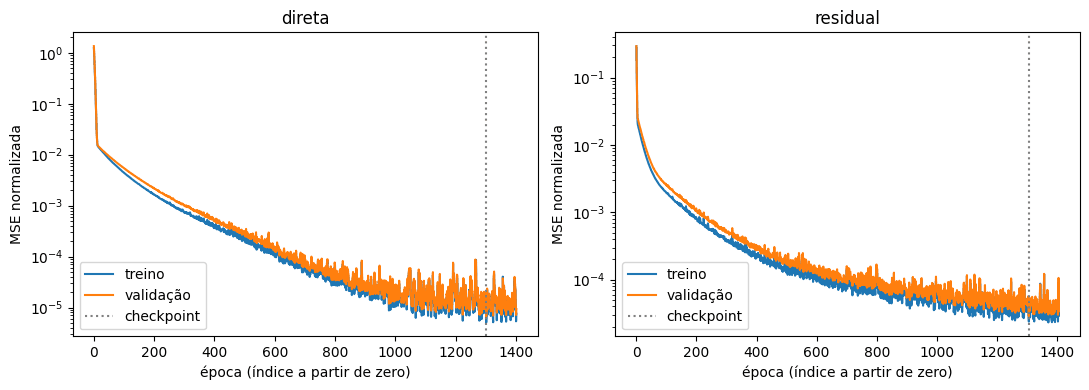

In [3]:
optimizer=torch.optim.Adam(P,lr=LR,betas=(.9,.999),eps=1e-8)
gens={s:torch.Generator().manual_seed(s+10000) for s in SEEDS}
rows=torch.arange(R)[:,None]
best=np.full(R,np.inf); best_epoch=np.zeros(R,int); stop=np.zeros(R,int)
best_P=[p.detach().clone() for p in P]; hist_train=[]; hist_val=[]
t0=time.perf_counter()
for epoch in range(1,EPOCHS+1):
    perm={s:torch.randperm(N_TRAIN,generator=gens[s]) for s in SEEDS}
    idx=torch.stack([perm[s] for m,p,s in configs]); active=stop==0
    for start in range(0,N_TRAIN,BATCH):
        ii=idx[:,start:start+BATCH]
        pred=forward(P,X[ii]); losses=(pred-A[rows,ii]).square().mean((1,2))
        optimizer.zero_grad(set_to_none=True); losses.sum().backward(); optimizer.step()
    with torch.no_grad():
        tr=(forward(P,X.expand(R,-1,-1))-A).square().mean((1,2)).numpy()
        va=(forward(P,Xv.expand(R,-1,-1))-Av).square().mean((1,2)).numpy()
        assert np.isfinite(tr[active]).all() and np.isfinite(va[active]).all()
        hist_train.append(np.where(active,tr,np.nan)); hist_val.append(np.where(active,va,np.nan))
        improve=active & (va<best); best[improve]=va[improve]; best_epoch[improve]=epoch
        for dest,src in zip(best_P,P): dest[improve]=src.detach()[improve]
        stop[active & (epoch-best_epoch>=PATIENCE)]=epoch
    if np.all(stop>0): break
stop[stop==0]=epoch
elapsed=time.perf_counter()-t0
print(f'Treino conjunto: {elapsed:.2f} s, {epoch} épocas globais; {R} redes.')
print('Melhores épocas por modo/ruído/semente:',best_epoch.reshape(2,5,3))
print('Épocas efetivas:',stop.reshape(2,5,3))
fig,ax=plt.subplots(1,2,figsize=(11,4))
for j,m in enumerate(MODES):
    i=configs.index((m,0,156)); ax[j].semilogy(np.array(hist_train)[:,i],label='treino'); ax[j].semilogy(np.array(hist_val)[:,i],label='validação')
    ax[j].axvline(best_epoch[i]-1,ls=':',color='gray',label='checkpoint'); ax[j].set(title=m,xlabel='época (índice a partir de zero)',ylabel='MSE normalizada'); ax[j].legend()
plt.tight_layout(); plt.show()

## 4. Predição nas unidades físicas e avaliação

Desnormalizamos o alvo antes de realimentar o modelo. Na residual, adicionamos o estado atual. O rollout recebe o estado verdadeiro somente no início. Usamos a mesma entrada histórica $u_k=0.8\sin(0.2k)$ e 500 passos (5 s). A condição inicial interna é $(-0.6,0.6)$ e a parcialmente externa é $(-0.6,1.4)$. Um estado que começa dentro pode sair da região de treino; registramos a fração de passos fora dela. Excluímos o estado inicial dos RMSEs do rollout. Qualquer trajetória não finita ou com módulo acima de $10^6$ é sinalizada como falha; não a removemos da média silenciosamente.

Relatamos RMSE, MAE e máximo absoluto por estado no teste one-step; no rollout, RMSE por estado e curvas. A persistência é a referência mínima. As médias são sobre as três sementes de inicialização, mantendo os dados fixos; não são intervalos de confiança sobre novas amostragens. A primeira semente é usada para os gráficos de trajetória, sem escolher o melhor resultado.

In [4]:
# Extração de redes individuais: inferência independente em NumPy.
weights=[p.numpy() for p in best_P]
def model(i,z):
    z=np.asarray(z,float); h=(z-zm)/zs
    for k in range(0,6,2):
        h=h@weights[k][i].T+weights[k+1][i]
        if k<4: h=np.tanh(h)
    out=h*ts[i]+tm[i]
    return out+z[...,:2] if res[i] else out

# Confere a desnormalização contra o forward em PyTorch.
with torch.no_grad():
    raw=forward(best_P,Xv.expand(R,-1,-1)).numpy()*ts[:,None,:]+tm[:,None,:]
    raw+=res[:,None,None]*Zv[None,:,:2]
assert all(np.allclose(model(i,Zv),raw[i],rtol=1e-12,atol=1e-12) for i in range(R))
U=.8*np.sin(.2*np.arange(500)); t=DT*np.arange(501)
x0s=[np.array([-.6,.6]),np.array([-.6,1.4])]
def rollout(fn,x0):
    xx=np.full((len(U)+1,2),np.nan); xx[0]=x0
    for k,u in enumerate(U):
        xx[k+1]=fn(xx[k],u)
        if not np.isfinite(xx[k+1]).all() or np.max(np.abs(xx[k+1]))>1e6:
            return xx,False
    return xx,True
real=[rollout(step,x)[0] for x in x0s]
base_tr=[rollout(lambda x,u:x,x)[0] for x in x0s]
base_one=rmse(Zt[:,:2],Yt); base_roll=[rmse(a[1:],b[1:]) for a,b in zip(base_tr,real)]
results=[]; trajectories={}
for i,(m,p,s) in enumerate(configs):
    pred=model(i,Zt); err=pred-Yt
    rr=dict(mode=m,noise=p,seed=s,one=rmse(pred,Yt),mae=np.abs(err).mean(0),max=np.abs(err).max(0))
    for j,x in enumerate(x0s):
        tr,ok=rollout(lambda x,u:model(i,np.r_[x,u]),x); trajectories[i,j]=tr
        rr[f'roll{j}']=rmse(tr[1:],real[j][1:]) if ok else np.full(2,np.inf)
        rr[f'outside{j}']=np.mean(np.any(np.abs(tr[1:])>1,axis=1)) if ok else np.nan
        rr[f'ok{j}']=ok
    results.append(rr)

def group(m,p,key): return np.stack([r[key] for r in results if r['mode']==m and r['noise']==p])
def avg(m,p,key): return group(m,p,key).mean(0)
def pair(a): return ' / '.join(f'{v:.6g}' for v in a)
def summary():
    lines=['| Modelo | Ruído | One-step RMSE x1 / x2 | Rollout interno | Rollout externo | Falhas |','|---|---:|---:|---:|---:|---:|',f'| persistência | — | {pair(base_one)} | {pair(base_roll[0])} | {pair(base_roll[1])} | 0 |']
    for m in MODES:
        for p in NOISES:
            fails=sum(not r['ok0'] or not r['ok1'] for r in results if r['mode']==m and r['noise']==p)
            lines.append(f'| {m} | {p}% | {pair(avg(m,p,"one"))} | {pair(avg(m,p,"roll0"))} | {pair(avg(m,p,"roll1"))} | {fails}/3 |')
    return '\n'.join(lines)
# Markdown tabela (o separador é uma quebra de linha real).
print(summary())
for m in MODES:
    print(m,'limpo: MAE',pair(avg(m,0,'mae')),'| máximo absoluto médio',pair(avg(m,0,'max')))
    print('  faixa de RMSE interno entre seeds:',pair(group(m,0,'roll0').min(0)),'a',pair(group(m,0,'roll0').max(0)))
    print('  frações fora (interno/externo):',avg(m,0,'outside0'),avg(m,0,'outside1'))
print('Fração da planta fora da região:',[np.mean(np.any(np.abs(a[1:])>1,axis=1)) for a in real])

| Modelo | Ruído | One-step RMSE x1 / x2 | Rollout interno | Rollout externo | Falhas |
|---|---:|---:|---:|---:|---:|
| persistência | — | 0.00573096 / 0.0121656 | 0.510066 / 0.506006 | 0.650007 / 1.31557 | 0 |
| direta | 0% | 0.00124015 / 0.0016477 | 0.0638233 / 0.0320928 | 0.0425108 / 0.0365799 | 0/3 |
| direta | 1% | 0.00339399 / 0.00381624 | 0.0852054 / 0.0760463 | 0.124398 / 0.0925343 | 0/3 |
| direta | 3% | 0.00652754 / 0.00722306 | 0.40008 / 0.263494 | 0.412725 / 0.266828 | 0/3 |
| direta | 5% | 0.009036 / 0.00936215 | 0.628059 / 0.566685 | 0.674899 / 0.588451 | 0/3 |
| direta | 10% | 0.0156671 / 0.0156637 | 0.429832 / 0.622013 | 0.575069 / 0.674929 | 0/3 |
| residual | 0% | 2.86956e-05 / 0.000111861 | 0.0028873 / 0.00198986 | 0.00198257 / 0.00359186 | 0/3 |
| residual | 1% | 0.000951223 / 0.00124104 | 0.045161 / 0.0264585 | 0.0460582 / 0.0142926 | 0/3 |
| residual | 3% | 0.00236867 / 0.00270744 | 0.172721 / 0.0753435 | 0.182873 / 0.0514362 | 0/3 |
| residual | 5% | 0.00361396 

## 5. Visualização dos resultados

Comparamos as trajetórias limpas com a planta e a persistência. Depois mostramos a média e a faixa entre seeds do RMSE de rollout em função do ruído. Os eixos logarítmicos permitem comparar ordens de magnitude. Os painéis são descritivos, não garantias de generalização global.

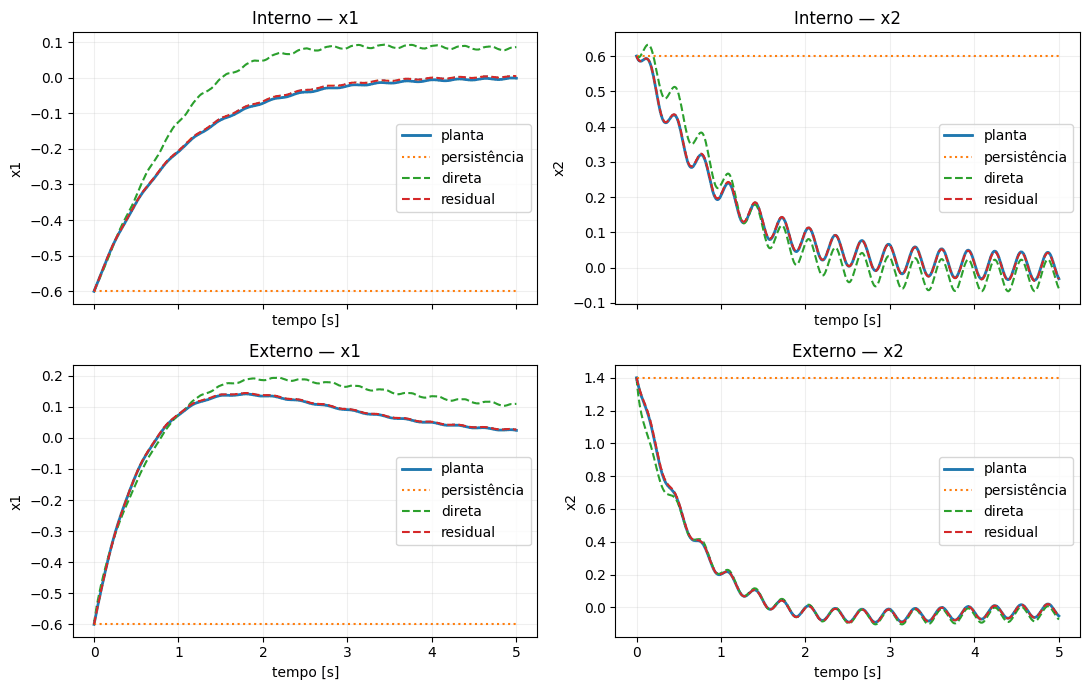

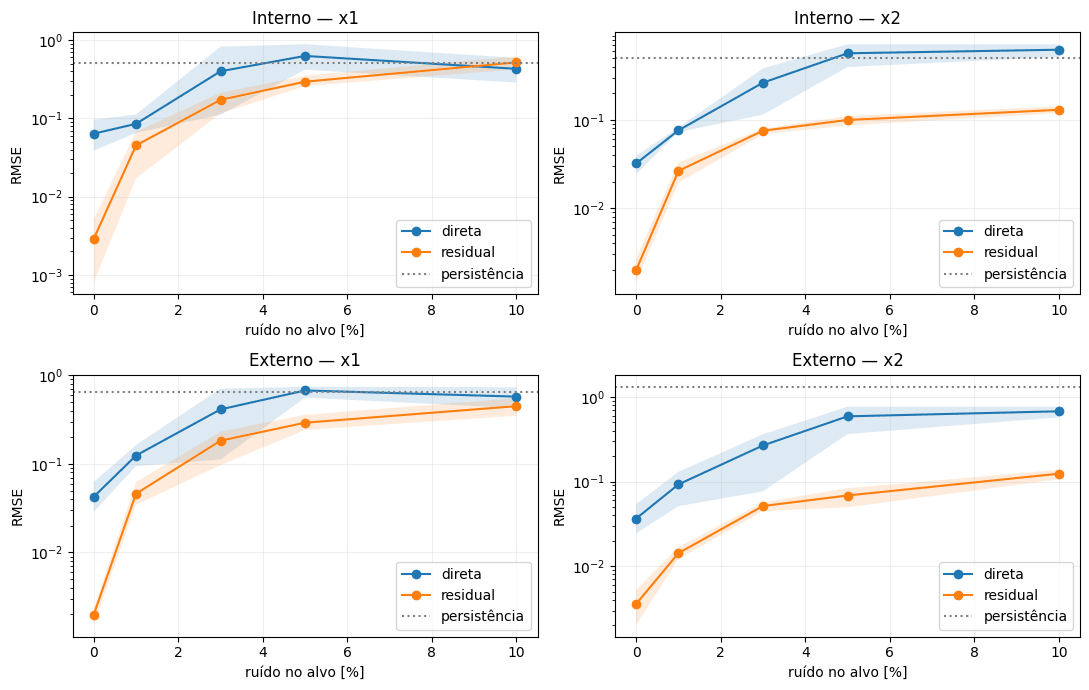

In [5]:
fig,ax=plt.subplots(2,2,figsize=(11,7),sharex=True)
for j in range(2):
    for k in range(2):
        a=ax[j,k]; a.plot(t,real[j][:,k],label='planta',lw=2); a.plot(t,base_tr[j][:,k],':',label='persistência')
        for m in MODES:
            i=configs.index((m,0,156)); a.plot(t,trajectories[i,j][:,k],'--',label=m)
        a.set(title=f'{["Interno","Externo"][j]} — x{k+1}',xlabel='tempo [s]',ylabel=f'x{k+1}'); a.grid(alpha=.2); a.legend()
plt.tight_layout(); plt.show()
fig,ax=plt.subplots(2,2,figsize=(11,7))
for j in range(2):
    for k in range(2):
        a=ax[j,k]
        for m in MODES:
            vals=np.array([group(m,p,f'roll{j}')[:,k] for p in NOISES]); finite=np.isfinite(vals).all(1)
            a.plot(np.array(NOISES)[finite],vals[finite].mean(1),'o-',label=m)
            a.fill_between(np.array(NOISES)[finite],vals[finite].min(1),vals[finite].max(1),alpha=.15)
        a.axhline(base_roll[j][k],ls=':',color='gray',label='persistência'); a.set(yscale='log',xlabel='ruído no alvo [%]',ylabel='RMSE',title=f'{["Interno","Externo"][j]} — x{k+1}'); a.legend(); a.grid(alpha=.2)
plt.tight_layout(); plt.show()

## 6. Equilíbrio e Jacobiano local

A planta tem equilíbrio na origem com $u=0$. Uma FNN sem restrições não necessariamente o preserva. Medimos $\|\hat F(0,0)\|_2$, procuramos um equilíbrio próximo com uma busca numérica iniciada na origem e só avaliamos $\rho(A_\theta)$ quando o resíduo é pequeno e o equilíbrio está no domínio de treino. O Jacobiano é obtido por diferenciação automática da rede **com** a desnormalização e a identidade residual. Para referência, a linearização contínua da planta na origem tem matriz $\left[\begin{smallmatrix}0&1\\-1&-2\end{smallmatrix}\right]$; o mapa RK4 possui raio espectral próximo de $e^{-0.01}$. Um raio espectral abaixo de 1 em um equilíbrio do mapa suave garante estabilidade assintótica **local do modelo**, não da planta controlada nem de todo o domínio. Uma busca de raiz malsucedida não prova que não há equilíbrio.

In [6]:
def jac(i,x):
    def f(q):
        z=torch.cat((q,torch.zeros(1,dtype=DTYPE))); h=(z-tensor(zm))/tensor(zs)
        for k in range(0,6,2):
            h=tensor(weights[k][i])@h+tensor(weights[k+1][i])
            if k<4: h=torch.tanh(h)
        y=h*tensor(ts[i])+tensor(tm[i]); return y+q if res[i] else y
    return torch.autograd.functional.jacobian(f,tensor(x)).numpy()
# RK4 polinômio da matriz linearizada da planta
Ac=np.array([[0.,1.],[-1.,-2.]])*DT
Ar=np.eye(2)+Ac+Ac@Ac/2+np.linalg.matrix_power(Ac,3)/6+np.linalg.matrix_power(Ac,4)/24
print('Raio espectral de referência RK4:',max(abs(np.linalg.eigvals(Ar))))
local=[]
for i,(m,p,s) in enumerate(configs):
    drift=np.linalg.norm(model(i,np.zeros(3))); sol=root(lambda x:model(i,np.r_[x,0.])-x,np.zeros(2))
    residual=np.linalg.norm(model(i,np.r_[sol.x,0.])-sol.x)
    valid=np.isfinite(sol.x).all() and residual<1e-9 and np.max(np.abs(sol.x))<=1
    rho=max(abs(np.linalg.eigvals(jac(i,sol.x)))) if valid else np.nan
    local.append((m,p,s,drift,sol.x.copy(),residual,rho))
    if p==0: print(f'{m:8s} seed={s}: drift={drift:.5g} x*={sol.x} res={residual:.2e} rho={rho:.8f}')
for m in MODES:
    for p in NOISES:
        rows_local=[r for r in local if r[0]==m and r[1]==p]; radii=np.array([r[-1] for r in rows_local]); valid=np.isfinite(radii)
        print(f'{m:8s} {p:2d}%: raízes válidas={valid.sum()}/3; rho<1={np.sum(radii<1)}/3; drift médio={np.mean([r[3] for r in rows_local]):.5g}')
# Cronometragem indicativa da inferência isolada (inclui normalização NumPy).
for m in MODES:
    i=configs.index((m,0,156)); z=Zt[0]; model(i,z)
    tic=time.perf_counter()
    for _ in range(3000): model(i,z)
    print(f'{m}: {(time.perf_counter()-tic)/3000*1e6:.2f} us por inferência individual (CPU, NumPy)')

Raio espectral de referência RK4: 0.9900498355659096
direta   seed=156: drift=0.00029237 x*=[ 0.1045935  -0.03474074] res=1.96e-17 rho=0.99380147
direta   seed=157: drift=0.00044281 x*=[-0.07692519  0.05055224] res=1.96e-17 rho=0.99395824
direta   seed=158: drift=0.00018163 x*=[0.01883235 0.00417342] res=8.18e-18 rho=0.99240783
residual seed=156: drift=2.3752e-05 x*=[ 0.00418973 -0.00114207] res=0.00e+00 rho=0.98998452
residual seed=157: drift=3.2817e-05 x*=[0.00208033 0.00053888] res=0.00e+00 rho=0.99161869
residual seed=158: drift=2.5609e-05 x*=[0.00153199 0.00045904] res=2.42e-19 rho=0.98995009
direta    0%: raízes válidas=3/3; rho<1=3/3; drift médio=0.0003056
direta    1%: raízes válidas=3/3; rho<1=3/3; drift médio=0.0010385
direta    3%: raízes válidas=2/3; rho<1=1/3; drift médio=0.0017388
direta    5%: raízes válidas=3/3; rho<1=1/3; drift médio=0.0046935
direta   10%: raízes válidas=2/3; rho<1=0/3; drift médio=0.0065032
residual  0%: raízes válidas=3/3; rho<1=3/3; drift médio=2.7

## 7. Limites e próximos passos

O protocolo testa identificação em estados completos, ruído apenas no alvo, uma região de treino, duas trajetórias históricas e três sementes com os mesmos dados. Não constitui uma comparação controlada com Koopman, SINDy ou GP sem reexecutá-los com as mesmas amostras e métricas. A normalização própria de cada alvo é um fator de confusão na comparação direta/residual. Para o próximo estudo: ablação com o mesmo peso físico na função de custo, treinamento com janelas multi-step, maior cobertura de estados, ruído nos estados medidos e restrições de estabilidade. Nenhuma garantia global ou de malha fechada foi estabelecida.

## 8. Resultados observados — execução de 27/11/2026

Execução completa: 30 redes, 1.964 épocas globais, 34,36 s de treinamento vetorial em CPU. Todos os rollouts foram finitos e abaixo do limite de falha. As métricas abaixo são médias das três sementes; os detalhes e gráficos estão nas células anteriores.

| Modelo (sem ruído) | RMSE one-step $x_1$ / $x_2$ | RMSE rollout interno | RMSE rollout externo |
|---|---:|---:|---:|
| Persistência | 0,005731 / 0,012166 | 0,51007 / 0,50601 | 0,65001 / 1,31557 |
| FNN direta | 0,001240 / 0,001648 | 0,06382 / 0,03209 | 0,04251 / 0,03658 |
| FNN residual | 0,00002870 / 0,00011186 | 0,002887 / 0,001990 | 0,001983 / 0,003592 |

**1. Parametrização.** Com dados limpos, o RMSE one-step de $x_1$ foi aproximadamente 43 vezes menor na residual e o RMSE do rollout interno, 22 vezes menor. Isso favorece a hipótese de aprender o incremento quando o mapa está próximo da identidade. Contudo, a normalização diferente dos alvos também altera o custo físico. Atribuir todo o ganho à conexão residual seria incorreto; a ablação com ponderação comum permanece pendente.

**2. Ruído.** Com 1% de ruído no alvo, o RMSE interno da residual em $x_1$ subiu de 0,00289 para 0,04516; com 10%, chegou a 0,51935, pior que a direta (0,42983) e ligeiramente pior que a persistência (0,51007). Em $x_2$, a residual manteve menor RMSE médio que a direta nos níveis testados. As curvas não são monotônicas em todos os casos; não há evidência de superioridade universal. Nos casos residuais com ruído de 5% e 10%, os melhores checkpoints ocorreram muito cedo (4 a 19 épocas), mostrando o papel da validação limpa neste cenário.

**3. Equilíbrio.** Sem ruído, todos os seis modelos apresentaram equilíbrio encontrado no domínio e raio espectral menor que 1. A norma média do deslocamento de um passo na origem foi 0,0003056 (direta) e 0,00002739 (residual), mas nenhuma arquitetura impõe equilíbrio exato. A planta tem raio espectral RK4 de 0,99004984. Com 10% de ruído, nenhum dos três modelos diretos apresentou raiz válida com raio espectral menor que 1; dois residuais apresentaram. Raiz não encontrada não equivale a instabilidade. Estes resultados são locais e condicionais ao equilíbrio encontrado.

**4. Extrapolação.** A condição inicial externa retorna rapidamente à região de treino: a planta passa apenas 4,2% dos 500 passos fora de $[-1,1]^2$. Portanto, esse teste é uma extrapolação inicial limitada, não uma validação de uma região externa inteira.

**Conclusão provisória:** a FNN residual foi a melhor referência limpa deste experimento. O resultado reforça a importância de escolher uma representação dinâmica orientada a controle, além da arquitetura e da MSE. Não há certificação global, comparação controlada com GP/Koopman/SINDy ou demonstração de robustez a ruído de processo. A próxima comparação deve usar a mesma ponderação física e explorar mais trajetórias e ruído de sensores.

Ambiente efetivamente utilizado: Python 3.13.5, PyTorch 2.10.0+cpu, NumPy 2.3.5, SciPy 1.17.0. O ambiente do repositório fixa outras versões de NumPy/SciPy; os resultados devem ser tratados como uma execução específica, e os tempos são indicativos, não benchmarks de tempo real.